# Математички методи за машинско учење 2025/2026
## Домаћи задатак број 5

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 05Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [2]:
import numpy as np
import numpy.random as rndm
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

**Задатак 1.** У многим AI алгоритмима користимо kernel матрицу или Грамову матрицу да бисмо мерили сличност између података. Да би алгоритам радио коректно, ова матрица мора бити позитивно дефинитна.

**a)**
Нека је дат скуп вектора (података)  
$$
x_1, x_2, \dots, x_n \in \mathbb{R}^d,
$$
смештених дуж врста матрице $X.$
Дефинишимо Грамову матрицу  
$$
G \in \mathbb{R}^{n \times n}
$$
тако да је  
$$
G_{ij} = x_i^T x_j.
$$

Доказати да је Грамова матрица  
$$
G = X X^T
$$
увек позитивно семидефинитна.

(5 поена)

 Matrica $G$ je pozitivno semidefinitna ako za svaki vektor $v \in \mathbb{R}^n$ važi
$$
v^T G v \geq 0.
$$

Za proizvoljan vektor $v \in \mathbb{R}^n$ možemo da napišemo:
$$
v^T G v = v^T (X X^T) v.
$$

Zbog asocijativnosti množenja matrica važi:
$$
v^T (X X^T) v = (v^T X)(X^T v).
$$

Zatim primećujemo da je
$$
v^T X = (X^T v)^T.
$$

Dakle:
$$
(v^T X)(X^T v) = (X^T v)^T (X^T v).
$$

Ovo je skalarni proizvod vektora sa samim sobom:
$$
(X^T v)^T (X^T v) = \| X^T v \|^2 \geq 0.
$$

Dakle, pošto je $\| X^T v \|^2 \geq 0$ za svaki $v \in \mathbb{R}^n$, sledi da je
$$
v^T G v \geq 0, \quad \forall v \in \mathbb{R}^n.
$$

Dakle, Gramova matrica $G = X X^T$ je uvek pozitivno semidefinitna.

**б)** Ако Грамовој матрици $G$ додамо члан $\lambda I$ (где је $\lambda > 0$), доказати да резултат постаје строго позитивно дефинитна матрица.  
Ово се у AI литератури назива **регуларизација Тихонова** или **Ridge**.

(5 поена)

Matrica $A$ je pozitivno definitna ako za svaki nenula vektor $v \in \mathbb{R}^n$ važi
$$
v^T A v > 0.
$$

Posmatrajmo matricu
$$
G_\lambda = G + \lambda I, \quad \lambda > 0.
$$

Za proizvoljan vektor $v \in \mathbb{R}^n$ imamo:
$$
v^T G_\lambda v = v^T (G + \lambda I) v.
$$

Razdvajamo:
$$
v^T (G + \lambda I) v = v^T G v + \lambda v^T I v.
$$

Znamo da je $v^T G v \geq 0$ (jer je $G$ pozitivno semidefinitna).  
Takođe,
$$
v^T I v = v^T v = \| v \|^2.
$$

Dakle:
$$
v^T G_\lambda v = v^T G v + \lambda \| v \|^2.
$$

Pošto za svaki nenulti vektor $v$ važi $\| v \|^2 > 0$ i $\lambda > 0$ i $v^T G v \geq 0$ dobijamo
$$
v^T G v + \lambda \| v \|^2 > 0,
$$

odnosno
$$
v^T G_\lambda v > 0
$$
pa je matrica $G_{\lambda}$ pozitivno definitna.

***

**Задатак 2.** **Инверзни проблеми**

Инверзни проблеми (или повратни проблеми) су математички проблеми у којима, уместо да израчунамо резултат на основу улазних података (као код директних проблема), ми тражимо узрок, унутрашње карактеристике или параметре система на основу познатих мерења, података или ефеката на излазу.

То је процес враћања уназад - од онога што видимо (резултат) до онога што је то узроковало (параметре).

**Директан проблем:**  Знамо модел $K$ и улаз $x$, израчунавамо излаз  $y = Kx.$

Другим речима, знамо узрок (нпр. облик објекта, материјал) и модел како се он понаша.  
Израчунавамо резултат (нпр. како објекат изгледа на слици, како се шири топлота).

**Инверзни проблем:**  Знамо излаз $y$ и модел $K$, тражимо улаз $x = K^{-1}y.$


Знамо резултат (нпр. слику) и модел.  
Циљ је да пронађемо узрок (нпр. прави облик објекта, непознате карактеристике материјала).

**Особине инверзних проблема**

За разлику од директних проблема који су обично добро постављени (постоји јединствено решење), инверзни проблеми често **немају јединствено решење**, или су решења **веома осетљива на грешке у подацима** (лоше условљени).

Жак Адамар је дефинисао да је инверзни проблем **коректно постављен (well-posed)** ако су испуњени следећи услови:

1. **Решење постоји.**  
2. **Решење је јединствено.**  
3. **Решење је стабилно** или добро условљено (непрекидно зависи од података $y$).

Ако било који од ових услова није испуњен (што је најчешћи случај у вештачкој интелигенцији и обради сигнала), кажемо да је проблем **некоректно постављен (ill‑posed)** према Адамару.

**а)** Нека је $K \in M_{n \times n}$ симетрична, позитивно дефинитна матрица са сопственим вредностима  
$$
\lambda_1 \ge \lambda_2 \ge \cdots \ge \lambda_n > 0
$$
и одговарајућим ортонормираним сопственим векторима  
$$ q_1, \dots, q_n.$$
Спектрална декомпозиција матрице гласи:
$$
K = Q \Lambda Q^T,
$$
где је $\Lambda = \mathrm{diag}(\lambda_1, \dots, \lambda_n)$.

Показати да се решење $x$ инверзног проблема може записати у облику
$$
x = \sum_{i=1}^{n} \frac{1}{\lambda_i} (q_i^T y)\, q_i.
$$
Коју врсту трансформације вектора $y$ представља израз $(q_i^T y)\, q_i?$ 

(5 поена)

Polazimo od osnovne jednačine direktnog problema:
$$y = Kx$$

Treba naći $$x = K^{-1}y$$

Znamo da je spektralna dekompozicija matrice $K$ data kao:
$$K = Q\Lambda Q^T$$

gde je $Q$ ortogonalna matrica čije su kolone ortonormirani sopstveni vektori $q_1, \dots, q_n$, a $\Lambda$ je dijagonalna matrica sa sopstvenim vrednostima na dijagonali $\mathrm{diag}(\lambda_1, \dots, \lambda_n)$.

Pošto je matrica $Q$ ortogonalna, važi da je njena inverzna matrica jednaka njenoj transponovanoj matrici: $Q^{-1} = Q^T$. Takođe, inverzna matrica dijagonalne matrice $\Lambda$ je jednostavno dijagonalna matrica čiji su elementi recipročne vrednosti originalnih: $\Lambda^{-1} = \mathrm{diag}(\frac{1}{\lambda_1}, \dots, \frac{1}{\lambda_n})$.

Sada možemo da nađemo inverz matrice $K$ (inverzna matrica proizvoda je proizvod pojedinačnih inverznih matrica, ali u suprotnom redosledu):
$$K^{-1} = (Q\Lambda Q^T)^{-1} = (Q^T)^{-1}\Lambda^{-1}Q^{-1} = Q\Lambda^{-1}Q^T$$

Zamenimo ovaj izraz u jednačinu za $x$:
$$x = Q\Lambda^{-1}Q^T y$$

Da bismo ovo zapisali u obliku sume, možemo da razložimo množenje matrica. Vektor $y$ se prvo množi sa $Q^T$. Pošto su redovi matrice $Q^T$ zapravo transponovani vektori $q_i^T$, rezultat $Q^T y$ je vektor-kolona čiji su elementi skalarni proizvodi $q_i^T y$:
$$Q^T y = \begin{bmatrix} q_1^T y \\ q_2^T y \\ \vdots \\ q_n^T y \end{bmatrix}$$

Zatim se ovaj vektor množi dijagonalnom matricom $\Lambda^{-1}$, što znači da se svaki $i$-ti element vektora množi sa $\frac{1}{\lambda_i}$:
$$\Lambda^{-1} Q^T y = \begin{bmatrix} \frac{1}{\lambda_1} q_1^T y \\ \frac{1}{\lambda_2} q_2^T y \\ \vdots \\ \frac{1}{\lambda_n} q_n^T y \end{bmatrix}$$

Na kraju, ovaj rezultat množimo sa matricom $Q$. Množenje matrice $Q$ vektorom-kolonom je ekvivalentno linearnoj kombinaciji kolona matrice $Q$ (a to su vektori $q_i$), gde su koeficijenti elementi tog vektora-kolone. Prema tome, dobijamo:
$$x = \sum_{i=1}^n \left( \frac{1}{\lambda_i} q_i^T y \right) q_i = \sum_{i=1}^n \frac{1}{\lambda_i} (q_i^T y) q_i$$

Izraz $(q_i^T y) q_i$ predstavlja ortogonalnu projekciju vektora $y$ na pravac koji je određen sopstvenim vektorom $q_i$.

Ako posmatramo detaljnije:
* **$q_i^T y$** predstavlja standardni skalarni proizvod. Pošto je $q_i$ jedinični vektor (deo ortonormirane baze), ovaj skalarni proizvod predstavlja dužinu projekcije vektora $y$ na pravac vektora $q_i$.
* **$(q_i^T y) q_i$** - kada tu dužinu pomnožimo sa samim jediničnim vektorom $q_i$, dobijamo novi vektor istog pravca kao vektor $q_i$ i čija je dužina tačno jednaka projekciji.

Dakle, cela formula za $x$ praktično znači da vektor $y$ projektujemo na svaki od pravaca iz baze sopstvenih vektora, svaku projekciju skaliramo faktorom $\frac{1}{\lambda_i}$, i na kraju ih sve saberemo. 

Na osnovu toga možemo da vidimo potencijalni problem - ako postoje veoma male sopstvene vrednosti $\lambda_i$, faktor $\frac{1}{\lambda_i}$ postaje ogroman, pa i najmanja greška ili šum u merenju $y$ postaje drastično pojačana u rezultatu $x$.

**б)** Када уместо $y$ посматрамо зашумљене податке
$$
y_\varepsilon = y + \varepsilon,
$$
решење инверзног проблема постаје
$$
x_\varepsilon = K^{-1} y_\varepsilon = K^{-1}(y + \varepsilon)
= x + K^{-1}\varepsilon.
$$
Записати $K^{-1}\varepsilon$ по угледу на формулу из дела под а).
Нека је сопствена вредност $\lambda_n\approx0$ блиска нули. Шта се дешава са решењем када се подацима $y$ дода чак и минималан шум $\varepsilon$ у оваквим околностима? Сопствене вредности $\frac{1}{\lambda_i}$ инверзне матрице $K^{-1}$ посматрати као појачавач шума. Објаснити зашто ово крши Адамаров трећи услов о стабилности.

(5 поена)

Primenom potpuno iste formule iz dela pod $(a)$ na vektor šuma $\varepsilon$, dobijamo:
$$K^{-1}\varepsilon = \sum_{i=1}^n \frac{1}{\lambda_i} (q_i^T \varepsilon) q_i$$

Zamenom ovoga u jednačinu za $x_\varepsilon$, ukupno rešenje inverznog problema sa zašumljenim podacima postaje:
$$x_\varepsilon = x + \sum_{i=1}^n \frac{1}{\lambda_i} (q_i^T \varepsilon) q_i$$

Sopstvene vrednosti inverzne matrice, $\frac{1}{\lambda_i}$, u gornjoj sumi direktno se ponašaju kao pojačavači šuma. 

Kada je neka sopstvena vrednost izuzetno mala (npr. $\lambda_n \approx 0$), njena recipročna vrednost $\frac{1}{\lambda_n}$ postaje ekstremno velika. 

Čak i ako podacima dodamo minimalan, jedva primetan šum $\varepsilon$, njegova projekcija na pravac vektora $q_n$ (odnosno vrednost $q_n^T \varepsilon$) uglavnom neće biti tačno jednaka nuli. Kada se ova mala komponenta šuma pomnoži sa ogromnim faktorom pojačanja $\frac{1}{\lambda_n}$, greška "eksplodira".

Kao rezultat, član sabirka koji potiče od šuma:
$$\frac{1}{\lambda_n} (q_n^T \varepsilon) q_n$$
postaje dominantan, potpuno maskirajući pravo, korisno rešenje $x$. Krajnji rezultat $x_\varepsilon$ imaće besmisleno velike vrednosti i gubi svoju upotrebljivost.

Adamarov treći uslov definiše da rešenje mora biti stabilno, što matematički znači da ono mora neprekidno zavisiti od podataka $y$. Drugim rečima, male promene (greške/šum) u podacima ($y$) smeju da izazovu samo srazmerno male promene u rešenju $x$.

Međutim, ono što vidimo je da kada postoji $\lambda_n \approx 0$, veoma mala promena na ulazu (dodavanje šuma $\varepsilon$) izaziva ogromnu promenu na izlazu (ogroman vektor greške $K^{-1}\varepsilon$).

Pošto mala greška u merenju rezultuje potpuno pogrešnim rešenjem, uslov neprekidne zavisnosti nije ispunjen. Rešenje je nestabilno (loše uslovljeno), odnosno kažemo da je prema Adamaru ovaj inverzni problem nekorektno postavljen.

**в)** Да бисмо решили проблем нестабилности и обезбедили трећи Адамаров услов, користимо
**Тихоновљеву регуларизацију** у односу на величину проблема:
$$
(K + n\lambda I)x = y, \qquad \lambda > 0.
$$
Тада важи:
$$
K + n\lambda I = Q(\Lambda + n\lambda I)Q^T,
$$
$$
(K + n\lambda I)^{-1}
= Q(\Lambda + n\lambda I)^{-1}Q^T.
$$
Регуларизовано решење може да се запише у облику:
$$
x_\lambda
= \sum_{i=1}^{n} 
\frac{1}{\lambda_i + n\lambda}\,(q_i^T y)\, q_i.
$$
Описати на који начин фактор регуларизације утиче на фактор појачања шума.

(5 поена)

U neregularizovanom slučaju faktor pojačanja šuma je $$\frac{1}{\lambda_i}$$

U regularizovanom slučaju faktor postaje
$$
\frac{1}{\lambda_i + n\lambda}
$$


Kada je $\lambda_i$ veoma mala vrednost (npr. $\lambda_i \approx 0$), neregularizovani faktor $\frac{1}{\lambda_i}$ je ogroman i šum se snažno pojačava.

Dodavanjem $n\lambda$ u imenilac, ako se desi da je $\lambda_i$ veoma malo (blisko nuli), faktor pojačanja ostaje ograničen:
$$
\frac{1}{\lambda_i + n\lambda} \leq \frac{1}{n\lambda}
$$

Dakle, kad je sopstvena vrednost velika, onda vrednost $n\lambda$ ne utiče mnogo na rešenje, a ako je sopstvena vrednost bliska nuli, onda dodavanje $n\lambda$ na sopstvenu vrednost znatno pomaže da količnik $$
\frac{1}{\lambda_i + n\lambda}
$$ ne "eksplodira".

Time se sprečava nekontrolisano pojačavanje šuma i obezbeđuje stabilnost rešenja.

Na taj način se ispunjava treći Adamarov uslov o stabilnosti i problem postaje korektno postavljen (well‑posed).

**г)** У овом делу ћемо практично видети како регуларизација спречава "експлозију" шума која је карактеристична за некоректне проблеме. нПокренути код у наставку за креирање елемената инверзног проблема.

In [18]:
# 1. Формирање лоше условљене матрице K (димензије 50x50)
n = 50
A = np.random.randn(n, n)
U, S, Vt = np.linalg.svd(A)

# Вештачки постављамо сопствене вредности тако да експоненцијално опадају ка нули
# Ово моделује типичан инверзни проблем који је некоректно постављен
S = np.exp(-0.5 * np.arange(n)) 
K = U @ np.diag(S) @ U.T 

# 2. Правимо стварно решење 'x_true' и мерења 'y' са додатком малог шума
x_true = np.random.randn(n)
noise_level = 0.001
y_noisy = K @ x_true + noise_level * np.random.randn(n)

ВАШ ЗАДАТАК:
1. Израчунати наивно решење `x_naive = np.linalg.inv(K) @ y_noisy`
2. Израчунати регуларизовано решење `x_reg` за `lmbda = 0.01`  користећи формулу са спектралним филтрирањем (преко сопствених вредности)
3. Израчунати Еуклидску грешку за оба решења у односу на `x_true`.
4. Визуелизовати `x_true`, `x_naive` и `x_reg` на једном графику како бисте видели разлику.

(10 поена)

Euklidska greška naivnog rešenja: 24346614.354
Euklidska greška regularizovanog rešenja: 6.792


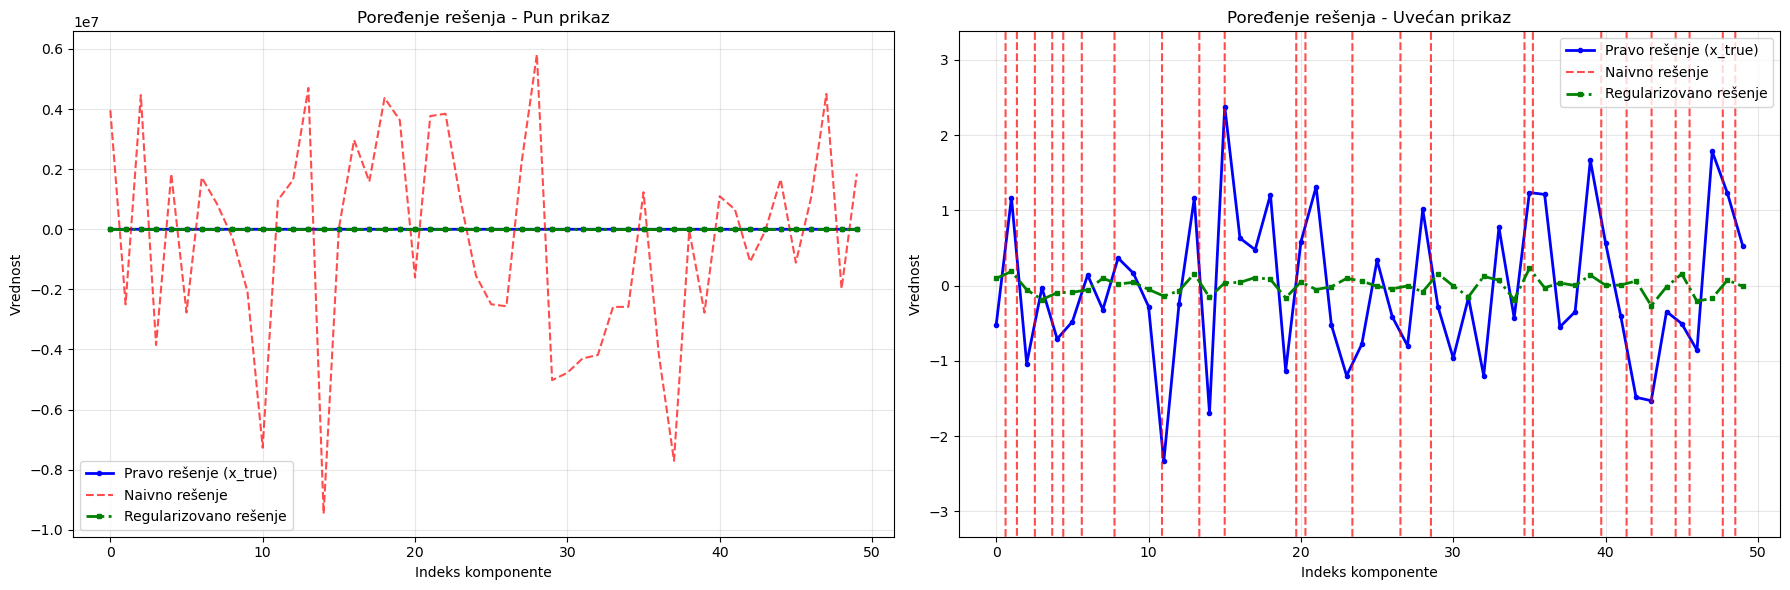

In [19]:
x_naive = np.linalg.inv(K) @ y_noisy

lmbda = 0.01

# koristimo U i S iz konstrukcije matrice K
# jer znamo da je K = U @ diag(S) @ U^T
# pa su U i S upravo sopstveni vektori i vrednosti od K
x_reg = np.zeros(n)
for i in range(n):
    lambda_i = S[i]
    q_i = U[:, i]
    faktor = 1.0 / (lambda_i + n * lmbda)
    projekcija = np.dot(q_i, y_noisy)
    x_reg += faktor * projekcija * q_i

error_naive = np.linalg.norm(x_naive - x_true)
error_reg = np.linalg.norm(x_reg - x_true)

print(f"Euklidska greška naivnog rešenja: {error_naive:.3f}")
print(f"Euklidska greška regularizovanog rešenja: {error_reg:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# grafik 1: pokazuje punu "eksploziju" šuma
ax1.plot(x_true, 'b-', linewidth=2, label='Pravo rešenje (x_true)', marker='o', markersize=3)
ax1.plot(x_naive, 'r--', linewidth=1.5, label='Naivno rešenje', alpha=0.7)
ax1.plot(x_reg, 'g-.', linewidth=2, label='Regularizovano rešenje', marker='s', markersize=3)
ax1.set_xlabel('Indeks komponente')
ax1.set_ylabel('Vrednost')
ax1.set_title('Poređenje rešenja - Pun prikaz')
ax1.legend()
ax1.grid(True, alpha=0.3)

# grafik 2: uvećan prikaz (fokus na x_true i x_reg)
ax2.plot(x_true, 'b-', linewidth=2, label='Pravo rešenje (x_true)', marker='o', markersize=3)
ax2.plot(x_naive, 'r--', linewidth=1.5, label='Naivno rešenje', alpha=0.7)
ax2.plot(x_reg, 'g-.', linewidth=2, label='Regularizovano rešenje', marker='s', markersize=3)
ax2.set_xlabel('Indeks komponente')
ax2.set_ylabel('Vrednost')
ax2.set_title('Poređenje rešenja - Uvećan prikaz')
ax2.legend()
ax2.grid(True, alpha=0.3)
y_min = min(x_true.min(), x_reg.min()) - 1
y_max = max(x_true.max(), x_reg.max()) + 1
ax2.set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

**д)** Када матрица $K$ није инвертибилна (сингуларна је), уместо $K^{-1}$ користимо Мур–Пенроузов псеудоинверз $K^{+}$.
Решење
$$
x_{MP} = K^{+} y
$$
је решење које минимизује норму остатка $\|Kx - y\|_2$, а међу свим таквим решењима
бира оно са најмањом нормом $\|x\|_2$.

ВАШ ЗАДАТАК:
1. Израчунати решење преко Мур-Пенроузовог псеудоинверза: `x_mp = np.linalg.pinv(K) @ y_noisy`
2. Израчунати решење преко Тихоновљеве регуларизације: `lmbda = 0.01`,  `x_reg = np.linalg.solve(K + n*lmbda*np.eye(n), y_noisy)`
3. Упоредити грешке:  `err_mp = np.linalg.norm(x_mp - x_true)`,  `err_reg = np.linalg.norm(x_reg - x_true)`
4. Нацртати графике и објаснити зашто `x_mp` "експлодира" (има велике вредности), док је `c_reg` глатко и близу `c_true`.

(10 поена)

Euklidska greška Moore-Penrose pseudoinverza: 24346610.460203
Euklidska greška Tihonovljeve regularizacije: 6.792363


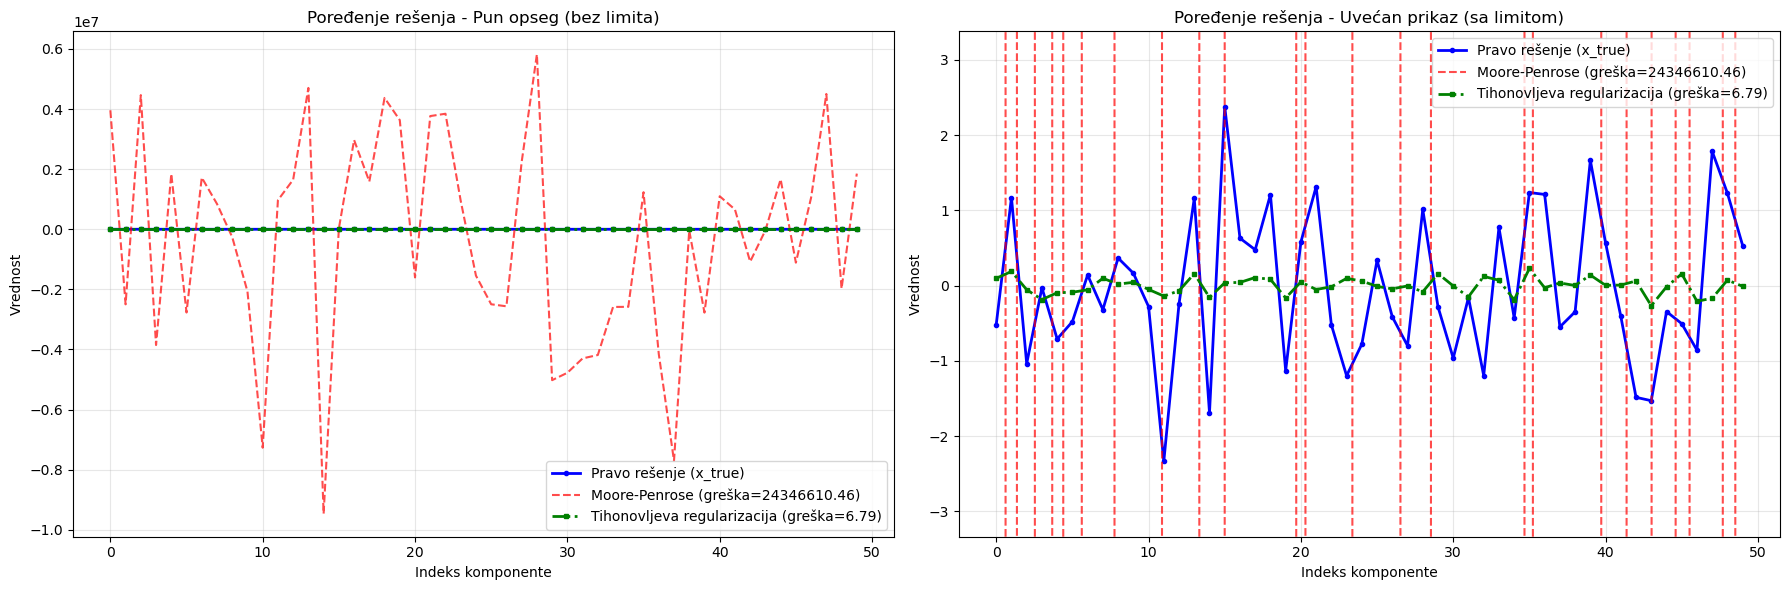

In [20]:
x_mp = np.linalg.pinv(K) @ y_noisy

lmbda = 0.01
x_reg = np.linalg.solve(K + n * lmbda * np.eye(n), y_noisy)

err_mp = np.linalg.norm(x_mp - x_true)
err_reg = np.linalg.norm(x_reg - x_true)

print(f"Euklidska greška Moore-Penrose pseudoinverza: {err_mp:.6f}")
print(f"Euklidska greška Tihonovljeve regularizacije: {err_reg:.6f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Grafik 1: BEZ limita (pokazuje punu "eksploziju" Moore-Penrose rešenja)
ax1.plot(x_true, 'b-', linewidth=2, label='Pravo rešenje (x_true)', marker='o', markersize=3)
ax1.plot(x_mp, 'r--', linewidth=1.5, label=f'Moore-Penrose (greška={err_mp:.2f})', alpha=0.7)
ax1.plot(x_reg, 'g-.', linewidth=2, label=f'Tihonovljeva regularizacija (greška={err_reg:.2f})', marker='s', markersize=3)
ax1.set_xlabel('Indeks komponente')
ax1.set_ylabel('Vrednost')
ax1.set_title('Poređenje rešenja - Pun opseg (bez limita)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Grafik 2: SA limitom (fokus na x_true i x_reg)
ax2.plot(x_true, 'b-', linewidth=2, label='Pravo rešenje (x_true)', marker='o', markersize=3)
ax2.plot(x_mp, 'r--', linewidth=1.5, label=f'Moore-Penrose (greška={err_mp:.2f})', alpha=0.7)
ax2.plot(x_reg, 'g-.', linewidth=2, label=f'Tihonovljeva regularizacija (greška={err_reg:.2f})', marker='s', markersize=3)
ax2.set_xlabel('Indeks komponente')
ax2.set_ylabel('Vrednost')
ax2.set_title('Poređenje rešenja - Uvećan prikaz (sa limitom)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Postavljanje y-limita na osnovu razumnog opsega
y_min = min(x_true.min(), x_reg.min()) - 1
y_max = max(x_true.max(), x_reg.max()) + 1
ax2.set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

Moore-Penrose pseudoinverz za simetričnu pozitivno definitnu matricu $K$ se može zapisati kao:

$$K^+ = \sum_{i=1}^{n} \frac{1}{\lambda_i} q_i q_i^T$$

pa je rešenje:

$$x_{MP} = K^+ y = \sum_{i=1}^{n} \frac{1}{\lambda_i} (q_i^T y) q_i$$

Problem nastaje kada su neke sopstvene vrednosti $\lambda_i$ veoma male (blizu nuli):

- Faktor $\frac{1}{\lambda_i}$ postaje VEOMA VELIK
- Čak i minimalan šum u $y$ se množi sa ovim ogromnim faktorom
- Rezultat je "eksplozija" - rešenje ima ekstremno velike vrednosti koje nemaju veze sa pravim rešenjem

Nasuprot tome, Tihonovljeva regularizacija koristi:

$$x_{reg} = (K + n\lambda I)^{-1} y = \sum_{i=1}^{n} \frac{1}{\lambda_i + n\lambda} (q_i^T y) q_i$$

Regularizacioni parametar $n\lambda$ "štiti" od eksplozije:

- Kada je $\lambda_i$ malo, faktor $\frac{1}{\lambda_i + n\lambda} \approx \frac{1}{n\lambda}$ ostaje ograničen
- Male sopstvene vrednosti ne mogu da stvore ogromne faktore pojačanja
- Komponente koje odgovaraju malim $\lambda_i$ se PRIGUŠUJU umesto da se pojačavaju
- Rezultat je glatko, stabilno rešenje blisko pravom rešenju

Zaključak: Moore-Penrose pseudoinverz ne rešava problem loše uslovljenosti - on samo omogućava
rešavanje singularnih sistema, ali i dalje je VEOMA OSETLJIV na šum. Regularizacija je
neophodna za stabilno rešenje inverznih problema.

***

**Задатак 3.** У претходном задатку смо анализирали апстрактну матрицу $K.$ У обради сигнала и слика, оператор замућења (blur) се често моделује као конволуција, која се у линеарној алгебри представља преко Теплицове матрице. Ово је типичан пример инверзног проблема: желимо да из замућеног и зашумљеног сигнала 
$y$ повратимо оригинални оштар сигнал $x.$

Дат је систем
$$
y = Ax + \varepsilon,
$$
где је $A$ матрица замућења, а $\varepsilon$ адитивни шум.
Користимо регуларизацију да пронађемо приближно решење оптимизационог проблема:
$$
\min_x \; \|Ax - y\|_2^2 + \lambda \|x\|_2^2.
$$
У машинском учењу, члан $ \lambda \|x\|_2^2 $ називамо $L_2$ регуларизацијом која спречава преприлагођавање (overfitting) тако што кажњава превелике вредности норме вектора $x$.

Проблем минимизације збира два квадрата $\|Ax - y\|_2^2 + \lambda \|x\|_2^2$ можемо записати као јединствен проблем најмањих квадрата коришћењем проширених  матрица.
Дефинишимо проширену матрицу $\tilde{A}$ и проширени вектор $\tilde{y}$ на следећи начин:
$ \tilde{A} = \begin{bmatrix} A \\ \lambda I \end{bmatrix}, \quad \tilde{y} = \begin{bmatrix} y \\ 0 \end{bmatrix}. $

**а)** Показати да важи следећа једнакост:
$ \|\tilde{A}x - \tilde{y}\|_2^2 = \|Ax - y\|_2^2 + \lambda \|x\|_2^2. $

(5 поена)

**б)** Из линеарне регресије знамо да проблем најмањих квадрата
$ \min_x \|\tilde{A}x - \tilde{y}\|_2^2 $
има решење дефинисано нормалним једначинама
$ \tilde{A}^T \tilde{A} x = \tilde{A}^T \tilde{y}. $

Израчунати производе блока матрица $\tilde{A}^T \tilde{A}$ и $\tilde{A}^T \tilde{y}$ и доказати да се добија систем:
$ (A^T A + \lambda I)x = A^T y. $

(5 поена)

**в)** Активирати код за симулацију замућења.

In [4]:
# 1. Генерисање оригиналног сигнала x (оштри скокови)
n = 100
x_true = np.zeros(n)
x_true[20:40] = 1.0
x_true[60:80] = 0.5

# 2. Формирање матрице замућења A (Gaussian blur)
c = np.exp(-np.linspace(0, 10, 10)**2 / 2) # Гаусово језгро
column = np.zeros(n)
column[:len(c)] = c
A = toeplitz(column)

# 3. Добијање замућеног сигнала y уз додатак малог шума
y_pure = A @ x_true
noise = np.random.normal(0, 0.05, n)
y = y_pure + noise

ВАШ ЗАДАТАК:  реализовати рестаурацију
1. Решити систем (A.T @ A + lmbda * I)x = A.T @ y за lmbda = 0.01
2. Израчунати решење преко псеудоинверза x_pinv = np.linalg.pinv(A) @ y
3. На истом графику приказати x_true, y, x_pinv и x_ridge (рестаурисан сигнал)

(15 поена)

**г)** На основу визуелног резултата, објасните зашто кажемо да регуларизација уводи пристрасност (bias) како би смањила варијансу (noise amplification). Како изгледа сигнал `x_ridge` у поређењу са `x_true` на местима где су скокови оштри?

(5 поена)

***

**Задатак 4.** СВД декомпозиција матрице $A \in M_{m \times n}$ ранга $r$ гласи
$ A = U \Sigma V^T. $

Матрицу $A$ можемо записати и као суму $r$ матрица ранга 1 (спољашњих производа):
$ A = \sum_{i=1}^{r} \sigma_i u_i v_i^T. $

Овај приказ нам омогућава да направимо апроксимацију ниског ранга $A_k$ тако што задржимо само првих $k$ највећих сингуларних вредности:
$ A_k = \sum_{i=1}^{k} \sigma_i u_i v_i^T, \quad k < r. $

**а)** На основу Екарт–Јанг–Мирски теореме, апроксимација $A_k$ је најбоља апроксимација ранга $k$ у смислу Фробенијусове норме.  

Питање: Колико износи квадрат грешке апроксимације $\|A - A_k\|_F^2$ изражен преко одбачених сингуларних вредности?

(5 поена)

б) У AI апликацијама често меримо проценат „сачуване информације“ (енергије) преко израза
$$ E(k) = \dfrac{\|A_k\|_F^2}{\|A\|_F^2}
       = \dfrac{\sum_{i=1}^{k} \sigma_i^2}{\sum_{i=1}^{r} \sigma_i^2}. $$
Ако желимо да компресујемо матрицу $A$ тако да сачувамо **95% информација**, потребно је изабрати најмањи број компоненти $k$ који задовољава услов?

In [5]:
import scipy.datasets as scd

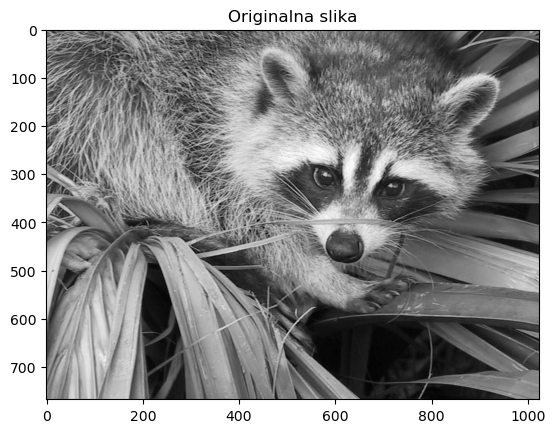

In [6]:
rakun=scd.face()
sk_vredn=rakun/255
A = sk_vredn @ [0.2126, 0.7152, 0.0722]
A.shape
plt.imshow(A, cmap="gray");
plt.title("Originalna slika");

ВАШ ЗАДАТАК:
1. Нацртати график сингуларних вредности (S) на логаритамској скали. Шта нам овај график говори о могућности компресије ове слике?
2. Нацртати график кумулативне енергије E(k) у функцији од k. Пронаћи најмање k за које је E(k) > 0.95 (95% енергије).
3. Реконструисати слику A_k за k = 5, 20, 50 и за k који даје 95% енергије.
4. Израчунати однос компресије за свако k.
   - Оригинал број података: m * n
   - Компресован број података: k * (m + n + 1)
   - Ratio = (m * n) / (k * (m + n + 1))
5. Приказати оригинале и реконструисане слике једу поред друге.

(5 поена)

**в)** Често мали пиксели (шум) утичу на најмање сингуларне вредности.
Покушајте да додате случајан шум слици:

In [7]:
A_noisy = A + 0.1 * np.random.randn(*A.shape)

Примените СВД и реконструишите слику са $k = 30$.

Објасните зашто СВД апроксимација ниског ранга може да послужи као метода за чишћење шума (denoising). Повежите ово са претходним задатком о регуларизацији и стабилности инверзних проблема.

(10 поена)

Да ли би СВД компресија подједнако добро радила на слици која представља чисто бели шум (random noise)? Зашто? (Помоћ: Размислите о брзини опадања сингуларних вредности).

(10 поена)

***